In [3]:
import os
import anndata as ad
import pandas as pd

spatial_dir = (
    "/compute/oven-0-13/jwinchel/"
    "split_spatial_chromium/split_xenium/"
)

files = sorted(
    f
    for f in os.listdir(spatial_dir)
    if f.endswith("annotated.h5ad") and f.startswith("GSM950")
)

result_dfs = []

for f in files:
    adata = ad.read_h5ad(
        os.path.join(spatial_dir, f),
        backed="r",
    )
    adata = adata[adata.obs['rctd_spot_class'].isin(['singlet','doublet_certain'])]

    sample_replicate = "_".join(f.split("_")[4:-2])

    for annotation_method in [
        "harmony_cell_type",
        "rctd_first_type",
    ]:
        if annotation_method not in adata.obs.columns:
            print(
                f"Warning: {annotation_method} not found in {f}"
            )
            continue

        counts = (
            adata.obs[annotation_method]
            .value_counts(dropna=False)
            .rename_axis("cell_type")
            .reset_index(name="count")
        )

        counts["sample_replicate"] = sample_replicate
        counts["annotation_method"] = annotation_method

        result_dfs.append(counts)

    adata.file.close()

results = pd.concat(
    result_dfs,
    ignore_index=True,
)

results["is_tcell"] = (
    results["cell_type"]
    .astype("string")
    .str.contains(r"\bT\b|T cell", case=False, na=False)
)

print(results)

                                  cell_type  count sample_replicate  \
0                            malignant cell  25398              B17   
1                        fibroblast of lung  11265              B17   
2                        smooth muscle cell   8056              B17   
3                        classical monocyte   5703              B17   
4                      fibroblast of breast   3995              B17   
..                                      ...    ...              ...   
565  CD4-positive, alpha-beta memory T cell    683             B1_3   
566               natural T-regulatory cell    648             B1_3   
567                               mast cell    575             B1_3   
568                    fibroblast of breast    446             B1_3   
569                     natural killer cell    335             B1_3   

     annotation_method  is_tcell  
0    harmony_cell_type      True  
1    harmony_cell_type     False  
2    harmony_cell_type     False  
3    ha

In [58]:
import os
import anndata as ad
import pandas as pd
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    cohen_kappa_score,
    accuracy_score,
)

spatial_dir = (
    "/compute/oven-0-13/jwinchel/"
    "split_spatial_chromium/split_xenium/"
)

files = sorted(
    f
    for f in os.listdir(spatial_dir)
    if f.endswith("annotated.h5ad") and f.startswith("GSM950")
)

agreement_rows = []
cell_level_rows = []

for f in files:
    sample_replicate = "_".join(f.split("_")[4:-2])

    adata = ad.read_h5ad(
        os.path.join(spatial_dir, f),
        backed="r",
    )

    obs = (
    adata.obs[
        ["harmony_cell_type", "rctd_first_type"]
    ]
    .dropna()
    .copy()
)

    # Convert categorical columns to ordinary strings
    obs["harmony_cell_type"] = (
        obs["harmony_cell_type"].astype(str)
    )

    obs["rctd_first_type"] = (
        obs["rctd_first_type"].astype(str)
    )

    obs["sample_replicate"] = sample_replicate

    obs["exact_agreement"] = (
        obs["harmony_cell_type"]
        .eq(obs["rctd_first_type"])
    )

    cell_level_rows.append(obs)

    agreement_rows.append({
        "sample_replicate": sample_replicate,
        "n_cells": len(obs),
        "exact_accuracy": accuracy_score(
            obs["harmony_cell_type"],
            obs["rctd_first_type"],
        ),
        "adjusted_rand_index": adjusted_rand_score(
            obs["harmony_cell_type"],
            obs["rctd_first_type"],
        ),
        "normalized_mutual_information":
            normalized_mutual_info_score(
                obs["harmony_cell_type"],
                obs["rctd_first_type"],
            ),
        "cohen_kappa": cohen_kappa_score(
            obs["harmony_cell_type"],
            obs["rctd_first_type"],
        ),
    })

    adata.file.close()

agreement_df = pd.DataFrame(agreement_rows)
cell_agreement_df = pd.concat(
    cell_level_rows,
    ignore_index=True,
)

print(agreement_df)

   sample_replicate  n_cells  exact_accuracy  adjusted_rand_index  \
0               B17    68181        0.599463             0.462447   
1               B16    15990        0.555660             0.328495   
2               B15    33494        0.546665             0.270846   
3               B14    77383        0.733456             0.772456   
4                B2   130957        0.719083             0.754714   
5               B13    37542        0.578152             0.528412   
6               B12   151364        0.752742             0.809656   
7               B11    79547        0.652583             0.673774   
8               B10    66079        0.633681             0.602543   
9                B4    37902        0.578070             0.422228   
10               B9    98081        0.716958             0.752075   
11               B8    48332        0.715447             0.672419   
12               B7    49557        0.688742             0.686987   
13               B6    94935      

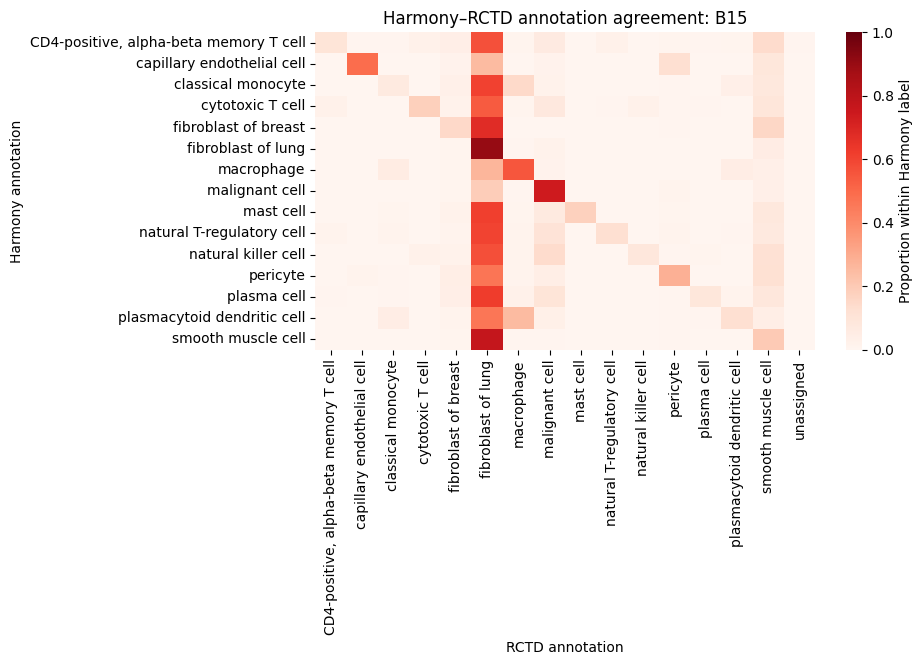

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

sample = "B15"

sample_df = cell_agreement_df.loc[
    # cell_agreement_df["sample_replicate"].eq(sample)
    cell_agreement_df["sample_replicate"].str.contains(sample)
]

confusion_counts = pd.crosstab(
    sample_df["harmony_cell_type"],
    sample_df["rctd_first_type"],
)

confusion_proportions = pd.crosstab(
    sample_df["harmony_cell_type"],
    sample_df["rctd_first_type"],
    normalize="index",
)

plt.figure(
    figsize=(
        max(6, 0.6 * confusion_proportions.shape[1]),
        max(6, 0.45 * confusion_proportions.shape[0]),
    )
)

sns.heatmap(
    confusion_proportions,
    cmap="Reds",
    vmin=0,
    vmax=1,
    cbar_kws={
        "label": "Proportion within Harmony label"
    },
)

plt.title(
    f"Harmony–RCTD annotation agreement: {sample}"
)
plt.xlabel("RCTD annotation")
plt.ylabel("Harmony annotation")
plt.tight_layout()
plt.show()

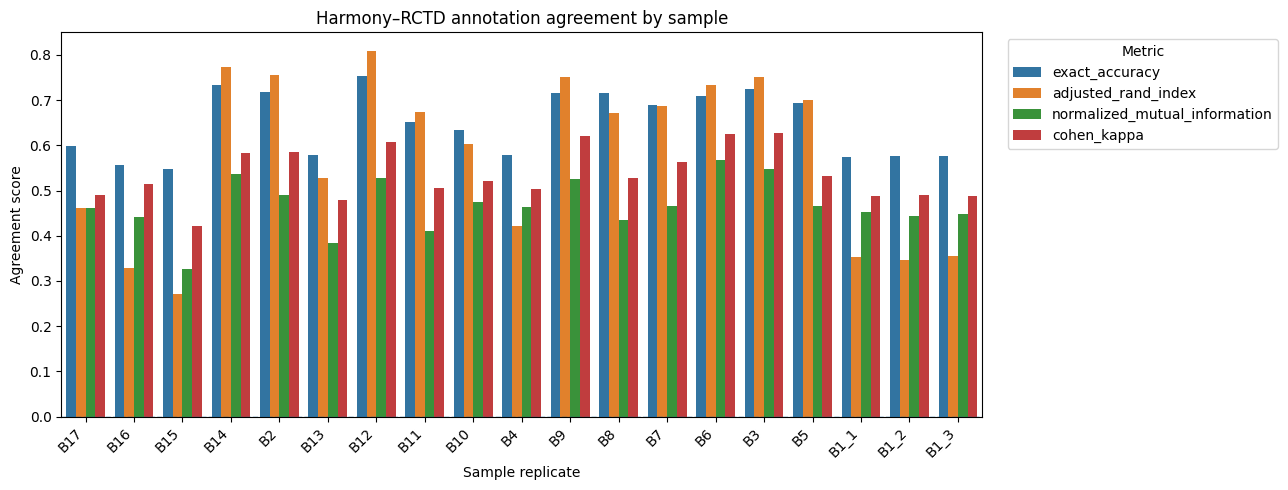

In [60]:
agreement_long = agreement_df.melt(
    id_vars=["sample_replicate", "n_cells"],
    value_vars=[
        "exact_accuracy",
        "adjusted_rand_index",
        "normalized_mutual_information",
        "cohen_kappa",
    ],
    var_name="metric",
    value_name="score",
)

plt.figure(figsize=(13, 5))

sns.barplot(
    data=agreement_long,
    x="sample_replicate",
    y="score",
    hue="metric",
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Sample replicate")
plt.ylabel("Agreement score")
plt.title("Harmony–RCTD annotation agreement by sample")
plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()
plt.show()

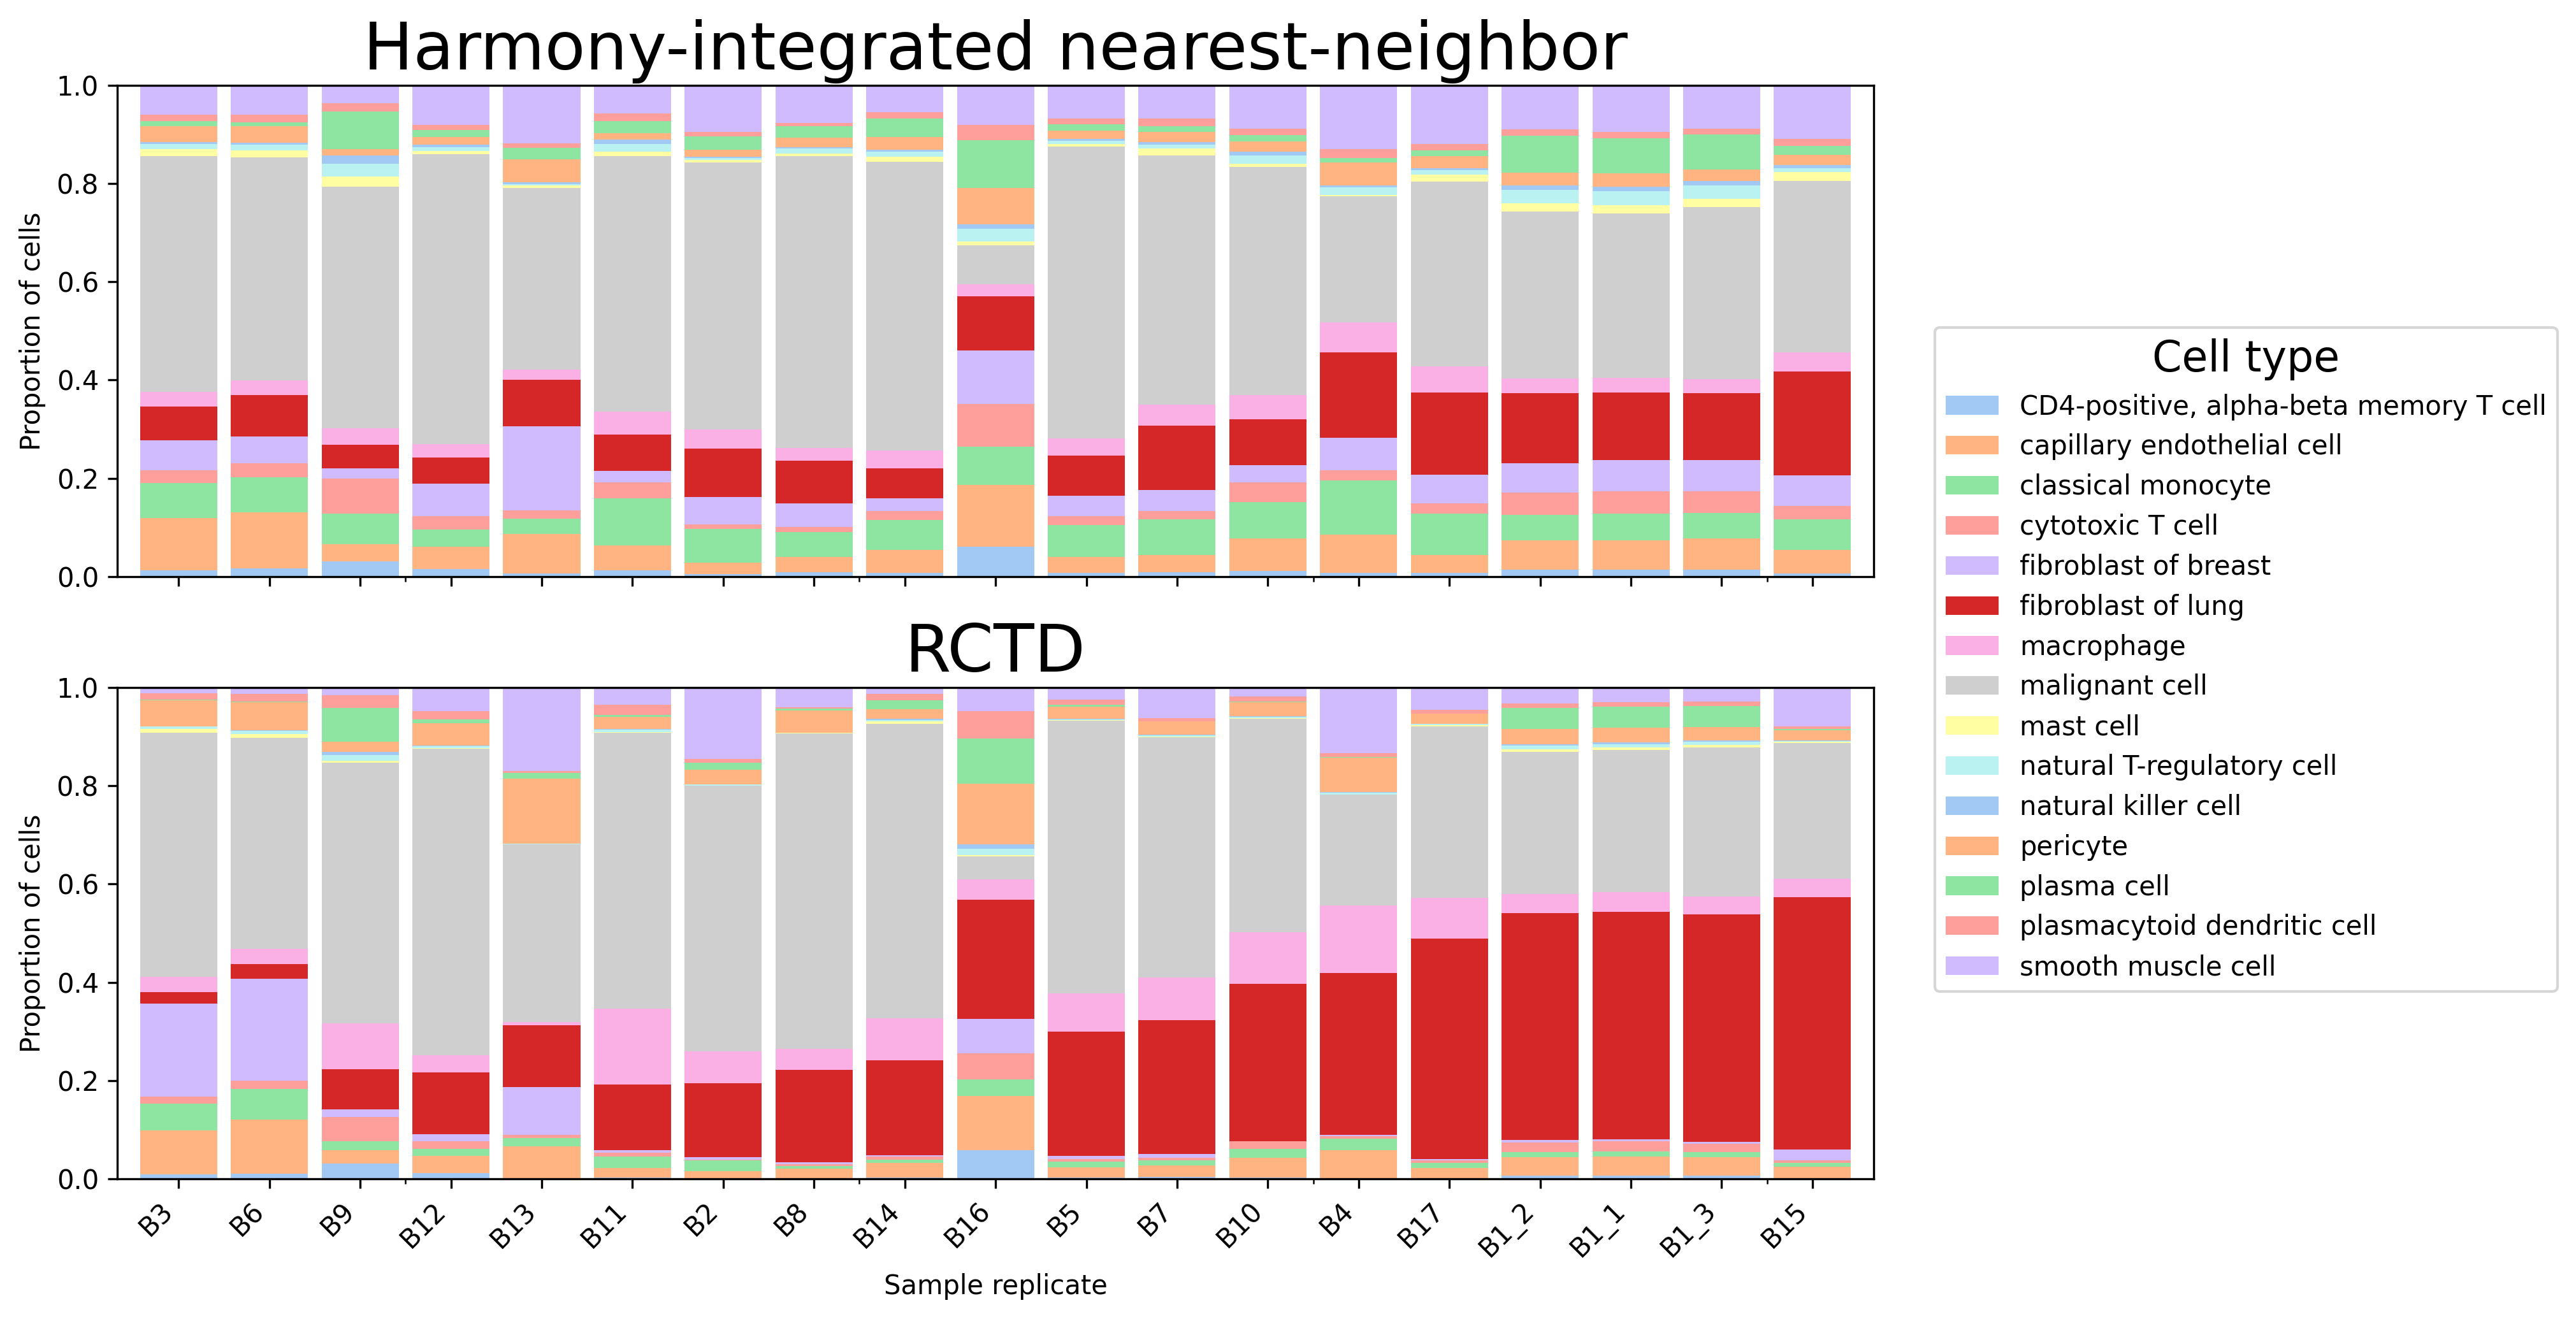

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

annotation_methods = [
    "harmony_cell_type",
    "rctd_first_type",
]

method_titles = {
    "harmony_cell_type": "Harmony-integrated nearest-neighbor",
    "rctd_first_type": "RCTD",
}

# Keep both annotation methods
plot_df = results.loc[
    results["annotation_method"].isin(annotation_methods)
].copy()

# Total number of cells for each sample and annotation method
sample_totals = (
    plot_df
    .groupby(
        ["annotation_method", "sample_replicate"],
        observed=True,
    )["count"]
    .transform("sum")
)

plot_df["cell_type_proportion"] = (
    plot_df["count"] / sample_totals
)

# Create one wide table for each annotation method
wide_tables = {}

for method in annotation_methods:
    wide_tables[method] = (
        plot_df.loc[
            plot_df["annotation_method"].eq(method)
        ]
        .pivot_table(
            index="sample_replicate",
            columns="cell_type",
            values="cell_type_proportion",
            fill_value=0,
            observed=True,
        )
    )

rctd_wide = wide_tables["rctd_first_type"]

if "fibroblast of lung" not in rctd_wide.columns:
    raise KeyError(
        "'fibroblast of lung' is not present in the RCTD annotations."
    )

# Ascending RCTD fibroblast proportion
sample_order = (
    rctd_wide["fibroblast of lung"]
    .sort_values(ascending=True)
    .index
    .tolist()
)

# Force B15 to the final position
if "B15" in sample_order:
    sample_order.remove("B15")
    sample_order.append("B15")

# Union of cell types used by either annotation method
cell_type_order = sorted(
    set(wide_tables["harmony_cell_type"].columns)
    | set(wide_tables["rctd_first_type"].columns)
)

# Assign colors in the existing cell_type_order
other_colors = sns.color_palette(
    "pastel",
    n_colors=len(cell_type_order),
)

cell_type_colors = dict(
    zip(cell_type_order, other_colors)
)

cell_type_colors["fibroblast of lung"] = "#d62728"

colors = [
    cell_type_colors[cell_type]
    for cell_type in cell_type_order
]

# Ensure samples and cell types have the same ordering
for method in annotation_methods:
    wide_tables[method] = (
        wide_tables[method]
        .reindex(
            index=sample_order,
            columns=cell_type_order,
            fill_value=0,
        )
    )

# colors = sns.color_palette(
#     "tab20",
#     n_colors=len(cell_type_order),
# )

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(10, 7),
    sharex=True,
    sharey=True,
    dpi=300
)

for ax, method in zip(axes, annotation_methods):
    wide_tables[method].plot(
        kind="bar",
        stacked=True,
        width=0.85,
        color=colors,
        ax=ax,
        legend=False,
    )

    ax.set_title(method_titles[method],fontsize=25)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion of cells")
    ax.set_ylim(0, 1)

axes[-1].set_xlabel("Sample replicate")
axes[-1].tick_params(
    axis="x",
    rotation=45,
)

for label in axes[-1].get_xticklabels():
    label.set_horizontalalignment("right")

# Single shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Cell type",
    bbox_to_anchor=(1.01, 0.5),
    loc="center left",
    title_fontsize=16,
)

# fig.suptitle(
#     "Cell-type composition by annotation method",
#     fontsize=30,
#     y=1.01,
# )

plt.tight_layout()
plt.show()

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Summarize total cells and T cells for each sample replicate
tcell_summary = (
    results
    .groupby("sample_replicate", observed=True)
    .apply(
        lambda df: pd.Series({
            "total_cells": df["count"].sum(),
            "tcell_total": df.loc[df["is_tcell"], "count"].sum(),
        }),
        include_groups=False,
    )
    .reset_index()
)

tcell_summary["non_tcell_total"] = (
    tcell_summary["total_cells"] - tcell_summary["tcell_total"]
)

tcell_summary["tcell_proportion"] = (
    tcell_summary["tcell_total"] / tcell_summary["total_cells"]
)

# Optional percentage column for display
tcell_summary["tcell_percent"] = (
    100 * tcell_summary["tcell_proportion"]
)

# Sort samples by T-cell proportion
tcell_summary = tcell_summary.sort_values(
    "tcell_proportion",
    ascending=False,
).reset_index(drop=True)

tcell_summary

,sample_replicate,total_cells,tcell_total,non_tcell_total,tcell_proportion,tcell_percent
0,B12,295024,192577,102447,0.652750,65.275028
1,B8,95194,60773,34421,0.638412,63.841208
2,B9,179782,113864,65918,0.633345,63.334483
3,B14,150652,94219,56433,0.625408,62.540823
4,B5,357852,214212,143640,0.598605,59.860501
5,B11,150254,87874,62380,0.584836,58.483634
6,B2,258160,143244,114916,0.554865,55.486520
7,B3,244770,131768,113002,0.538334,53.833395
8,B7,96772,51234,45538,0.529430,52.943000
9,B6,185374,92338,93036,0.498117,49.811732


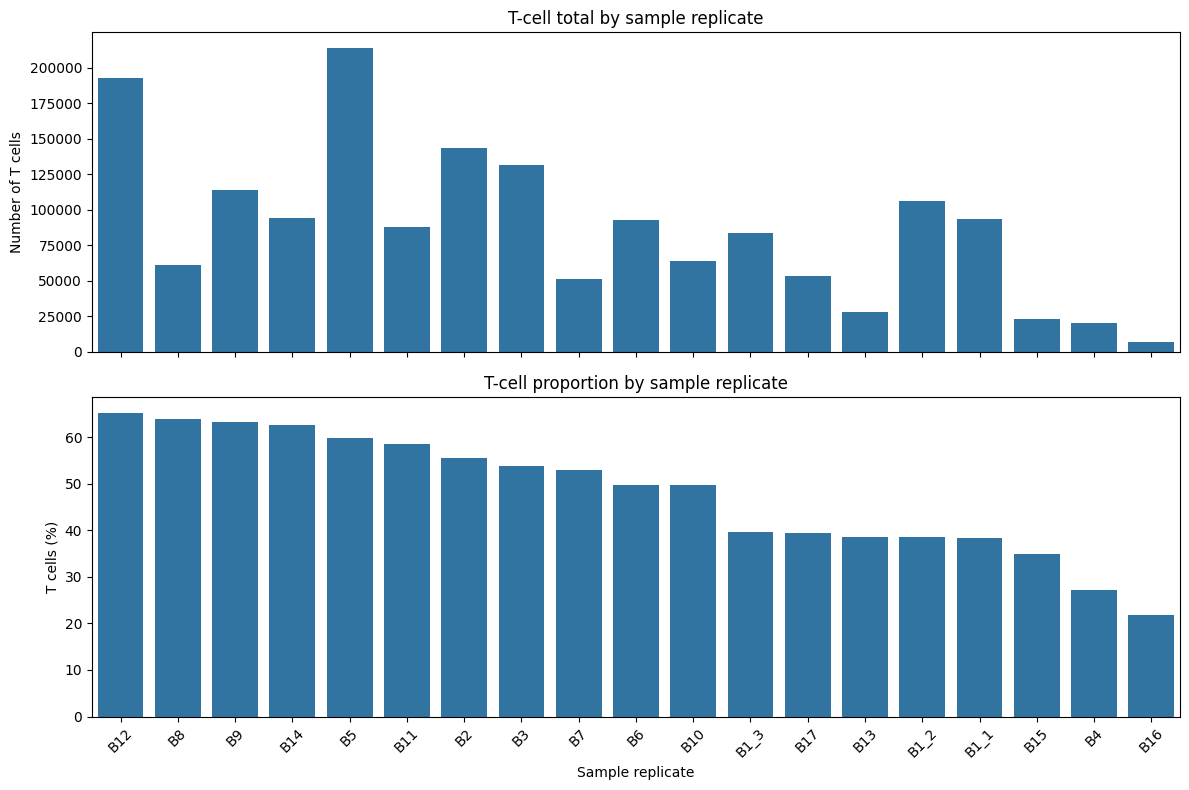

In [64]:
sample_order = tcell_summary["sample_replicate"]

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True,
)

# Absolute T-cell counts
sns.barplot(
    data=tcell_summary,
    x="sample_replicate",
    y="tcell_total",
    order=sample_order,
    ax=axes[0],
)

axes[0].set_title("T-cell total by sample replicate")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of T cells")

# T-cell proportions
sns.barplot(
    data=tcell_summary,
    x="sample_replicate",
    y="tcell_percent",
    order=sample_order,
    ax=axes[1],
)

axes[1].set_title("T-cell proportion by sample replicate")
axes[1].set_xlabel("Sample replicate")
axes[1].set_ylabel("T cells (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()